# ADEPT compact FL HDH-only analysis: CIFAR-10/CNN 16k, all client counts

This notebook analyzes the all-environment single-pattern configuration (`OFF,OFF,ON`) for the image task across all sampled client counts (4, 8 and 10). It follows the established ADEPT analysis sequence and uses the fixed campaign-wide tradeoff grid. No baseline or other pattern configuration is included.

- **RQ1 — Single-pattern tradeoff behavior:** Which accuracy–time regions occur with HDH enabled as the only pattern, and how do their observed frequencies and outcome distributions vary across client counts and sampled environments?
- **RQ2 — Single-pattern operating envelopes:** Which joint design and environmental conditions are associated with each observed region, and how do PRIM/CART box restrictions change held-out target rates, coverage and stability?

This is a profile of one deployable pattern configuration, not a comparison against baseline or other patterns. Dataset and model are treated as one paired task context. Results are observational associations. Environmental coverage is uneven, so observed relationships may reflect the sampled environment mix.


In [1]:
# Set project root in path so we can import 'adept' package
import sys
sys.path.append("../../..")
sys.path.append("../..")

import contextlib
import io
import itertools
import json
import pandas as pd
import matplotlib.pyplot as plt

from adept import PatternAnalysis
from adept.utils.linter import SystemLinter
from adept.utils.spec_summary import summarize_system

import fl_slices

# The spec declares how the per-client columns ("Client <N> <field>") are aggregated
# into system-level parameters and objectives (dataspace.aggregations, see
# adept/utils/aggregation.py); fl_slices.slice_filter only adds the pattern-stress
# columns and filters the runs.

In [2]:
# ---- Scenario and shared tradeoff parameters
SLICE = 'hdh'
INCLUDE_BASELINE = False
CLIENTS = None                 # retain 4, 8 and 10 clients
TASK = 'image'                 # CIFAR-10/CNN 16k
ENVIRONMENT = 'all'            # include all available environment settings
SPEC = '../FLsystem_compact_all.json'
TRADEOFF_LABELS = {
    'final_val_accuracy': ['S', 'M', 'L'],
    'avg_total_time': ['S', 'M', 'L'],
}
# Detected once on the full compact campaign and held fixed across all scenarios.
TRADEOFF_EDGES = {
    'final_val_accuracy': [0.2075, 0.4774, 0.7473, 1.0172],
    'avg_total_time': [1.5625, 9.5065, 17.4505, 25.3945],
}

PLOT_COLOR = '#ff7f0e'

from pathlib import Path
PLOT_DIR = Path('plots')
PLOT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_STEM = 'quality-space__task-image__hdh-only_OFF_OFF_ON__clients-all__environment-all'


## Analysis population: all-environment HDH-only configuration across client counts

This analysis includes only `OFF,OFF,ON` (HDH ON; the other two pattern decisions OFF) for the selected task, retaining all available client counts (4, 8 and 10) and every available environment setting. It excludes both `OFF,OFF,OFF` and all multi-pattern configurations. The environment design is not fully crossed, so the observed context mix is uneven. Results describe this single-pattern configuration across sampled client counts and operating conditions; they do not estimate its difference from another policy.


In [3]:
ENVIRONMENT = 'all'
print('Environment view:', ENVIRONMENT)

Environment view: all


## 1. Load System & Model Summary

We create a `PatternAnalysis` session from the system definition (`SPEC`) and load its runs through `fl_slices.slice_filter`, which adds the pattern-stress columns and keeps only the runs selected in the parameters cell. The spec declares how per-client columns are aggregated into run-level parameters and objectives (`dataspace.aggregations`).

The model summary (`summarize_system`) lists the system's decisions, policies, parameter bindings and configuration coverage, so they can be checked before any analysis builds on them.

In [4]:
session = PatternAnalysis(SPEC)
session.load(preprocessor=fl_slices.slice_filter(
    SLICE, INCLUDE_BASELINE, clients=CLIENTS, task=TASK, environment=ENVIRONMENT
))

print(f"Loaded {len(session.raw_df)} experiments.")
print()
print(summarize_system(session.sys_def))

Using CSV delimiter: ','
Loading source file: ../adept_experiments_all_waves.csv
Loaded 1380 rows.
Loading source file: ../adept_experiments_all_waves_combinedAP.csv
Loaded 960 rows.
Concatenated 2 files: 2340 rows.
Applying preprocessor hook to source data...


HDH instances: measured from the per-round data for 2340 of 2340 runs (HDH Time > 0); rule A3 for the others.
Slice: kept 150 of 2340 runs (configurations ['OFF,OFF,ON']; task 'image' (CIFAR-10 + CNN 16k)).
[WARNING] Dataspace.ConfigurationIdentification: Configurations defined in JSON but missing in Data: {'OFF,ON,ON', 'ON,OFF,ON', 'OFF,ON,OFF', 'ON,OFF,OFF', 'ON,ON,ON', 'OFF,OFF,OFF', 'ON,ON,OFF'}
[WARNING] Dataspace.QualityObjectives: Quality Objective 'RAM Usage Avg Mean' is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'N Rounds' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'Model' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'Dataset' (Component: fl_system) is low-variance: 100.0% of values are concentr

### The design space

`fl_system` is a single component that composes **three independent ON/OFF pattern decisions**:

| Decision | `OFF` | `ON` | Parameters bound by `ON` |
|:---|:---|:---|:---|
| `client_selector_pattern` | every client trains | only clients that meet a resource criterion train | `Client Selector Strategy`, `Criteria`, `Value` |
| `message_compressor_pattern` | messages are sent uncompressed | client messages are compressed | `Message Compressor Alg` |
| `hdh_pattern` | no data augmentation | clients augment their data with a generative model | the `HDH ...` settings |

Besides these pattern parameters (constraints), the spec declares:

- **levers**: system settings the architect controls, such as the model, dataset, number of clients and rounds, and the number of active pattern types;
- **uncertainties**: conditions the architect does not control, such as the shares of low-spec, non-IID and delayed clients, client resources, data heterogeneity, and the number of deployed pattern instances;
- **quality objectives**: model quality (F1 and accuracy, maximize) and cost (training, communication and total round time, CPU and RAM usage, minimize).

### Reading the model summary

- **Configurations.** A configuration fixes one policy per decision, written `client_selector,message_compressor,hdh` (for example `OFF,OFF,OFF` is the baseline). The analysis describes configurations present in the loaded runs; variation by pattern composition can be examined only where combinations were run.
- **Runs per configuration.** When the counts differ, results pooled over configurations (per decision, or per stress level) weight the configurations unequally.
- **Parameters that vary.** Only parameters with more than one value in the loaded runs can explain differences between runs. Each filter in the parameters cell (`CLIENTS`, `TASK`, ...) turns the factor it fixes into a constant.
- **Pattern parameters** have a single value when their pattern is ON and are empty when it is OFF, so each one records *whether* its pattern is on rather than a tunable value.

The analysis targets **model accuracy × total round time** (`final_val_accuracy` × `avg_total_time`), the classic FL tradeoff (Section 3).

## 2. Linter Sanity Check

`SystemLinter` checks the spec against the loaded data. It runs on `session.raw_df` (parameters and objectives) rather than `session.experiments_df` (parameters only), which lacks the objective columns and would report every objective as missing; `session.load()` lints the same combined frame.

The notebook stops if the linter reports an `ERROR`. `WARNING`s do not stop it; the next cell explains how to read them.

In [5]:
issues = SystemLinter().lint(session.sys_def, session.raw_df)
errors = [i for i in issues if i.level == "ERROR"]
warnings_ = [i for i in issues if i.level == "WARNING"]

print(f"Linter findings: {len(errors)} ERROR(s), {len(warnings_)} WARNING(s)")
for issue in issues:
    print(" ", issue)

assert not errors, f"Linter reported ERROR-level issues; fix the spec before proceeding: {errors}"

Linter findings: 0 ERROR(s), 32 WARNING(s)
  [WARNING] Dataspace.ConfigurationIdentification: Configurations defined in JSON but missing in Data: {'OFF,ON,ON', 'ON,OFF,ON', 'OFF,ON,OFF', 'ON,OFF,OFF', 'ON,ON,ON', 'OFF,OFF,OFF', 'ON,ON,OFF'}
  [WARNING] Dataspace.QualityObjectives: Quality Objective 'RAM Usage Avg Mean' is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'N Rounds' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Model' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Dataset' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Optimizer' (Component: fl_system) is low-variance: 100.0% of values are 

### Reading the linter warnings

| Warning | What it means for the analysis |
|:---|:---|
| **Policy-combination coverage** | Some configurations are not in the loaded runs. Conclusions apply only to the configurations present. Expected for slices that keep only some configurations. |
| **Low variance near 100%** | The parameter has (almost) one value in these runs, so it cannot explain differences between runs, and feature scoring (Section 8) gives it (near) zero importance. Expected for factors fixed by the experiment design or by the slice. |
| **Low variance on pattern parameters** | Their most frequent value is "not selected": they are empty whenever their pattern is OFF. They carry "pattern on or off", not a tunable value. |
| **Low variance on an objective** | Most runs share one value, so the objective separates runs poorly as a tradeoff axis. |
| **Missing values (NaN semantics)** | A parameter has missing values but is not declared `optional`, or an objective has missing values (see `docs/nan_strategy.md`). Resolve these in the spec or the data before reading the results. |

> Warnings explained by the experiment design or the slice are expected. Any other warning points to a spec or data issue.

In [6]:
print(f"Loaded {len(session.raw_df)} experiments.")
session.raw_df.head()

Loaded 150 experiments.


,N Rounds,Total Clients,Model,Dataset,Optimizer,Learning Rate,Batch Size,Epochs,Client 1 ID,Client 1 CPU,...,HDH Instances,Pattern Instances,CPU Mean,RAM Mean,Data Distribution Diversity,Data Persistence Diversity,Alpha Dirichlet Mean,JSD Mean,CPU Usage Avg Mean,RAM Usage Avg Mean
0,20,4,CNN 16k,CIFAR-10,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.875,0.00,647.5125,0.0
1,20,4,CNN 16k,CIFAR-10,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.750,0.02,694.7375,0.0
2,20,4,CNN 16k,CIFAR-10,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.625,0.05,691.2625,0.0
3,20,8,CNN 16k,CIFAR-10,Adam,0.001,64,1,Client 1,12,...,1,1,10.75,4.0,2,1,0.875,0.01,616.5875,0.0
4,20,8,CNN 16k,CIFAR-10,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.750,0.04,626.4250,0.0


## 3. Define Tradeoffs

The spec declares several quality objectives. Discretizing all of them combinatorially would create far more regions than there are runs, and most would be empty. We discretize the **classic FL tradeoff**, with the bins given in `TRADEOFF_LABELS`:

- **model accuracy**: `final_val_accuracy`, the accuracy of the global model after the last round (maximize);
- **total round time**: `avg_total_time`, the average wall-clock time of a round, training plus communication (minimize).

The F1 objectives stay in the spec and can replace accuracy as a robustness check.

Bin edges come from the parameters cell. With `TRADEOFF_EDGES = None` they are detected from the loaded runs (equal-width bins over the observed range, padded by 0.1). With explicit edges, every notebook that uses them shares the same regions, so their results can be compared.

In [7]:
# ---- Discretization of the objectives (labels and edges: see the parameters cell)
tradeoffs, schemes = session.create_tradeoffs(
    method='discretization', labels=TRADEOFF_LABELS, edges=TRADEOFF_EDGES
)

print(len(tradeoffs), "possible tradeoffs (regions)")
for scheme in schemes:
    print(f"Objective: {scheme.objective_name}")
    print("  edges:", [scheme.bins[0].min_value] + [b.max_value for b in scheme.bins])
    for b in scheme.bins:
        print(f"  {b.label}: [{b.min_value:.2f}, {b.max_value:.2f}]")


Creating discretization tradeoffs with 3 bins.
9 possible tradeoffs (regions)
Objective: final_val_accuracy
  edges: [0.2075, 0.4774, 0.7473, 1.0172]
  S: [0.21, 0.48]
  M: [0.48, 0.75]
  L: [0.75, 1.02]
Objective: avg_total_time
  edges: [1.5625, 9.5065, 17.4505, 25.3945]
  S: [1.56, 9.51]
  M: [9.51, 17.45]
  L: [17.45, 25.39]


### Reading the tradeoffs

- **Names.** A tradeoff (region) is named `<accuracy bin>-<time bin>`. `L-S` (high accuracy, fast) is the ideal region and `S-L` (low accuracy, slow) the worst.
- **Edges.** The cell prints the edges of each objective. Check whether they were detected on these runs or fixed (parameters cell): the fixed edges make regions comparable across client counts and tasks.
- **Populated regions.** The split (Section 4) and the objective-space plot show how many runs each region holds. Regions with few runs yield boxes that are hard to validate; empty regions get no box.
- **Effects of the factors.** To see how a pattern moves the objectives, compare mean accuracy and round time per configuration under the same task and client count (Section 7 gives these tables). Pooling over tasks or client counts lets those factors dominate the comparison.

## 4. Data Splitting

We split the runs into train and test sets, stratified by tradeoff region: feature scoring (Section 8) and box discovery use the training runs, and boxes and robustness are evaluated on the test runs (Sections 9-11).

## Research Question 1 — What tradeoffs occur with HDH as the only enabled pattern?

The following sections describe objective distributions and the fixed tradeoff regions for this one configuration, then show how observed outcomes vary across client counts and sampled environments. With only one pattern policy in the data, the tables characterize its behavior rather than compare design policies.


In [8]:
session.split_data(test_size=0.3, random_state=42, remove_outliers=False, verbose=True, group_column='partition_seed')

Grouped split by partition_seed: 3 of 10 groups held out; stratification score=0.000425.
Data split: 105 train, 45 test.

--- Train Set Tradeoff Counts ---
  S,S: 2 (1.90%)
  S,M: 57 (54.29%)
  M,S: 1 (0.95%)
  M,M: 45 (42.86%)

--- Test Set Tradeoff Counts ---
  S,S: 0 (0.00%)
  S,M: 25 (55.56%)
  M,S: 0 (0.00%)
  M,M: 20 (44.44%)


### Reading the split

- **Grouped holdout.** All rows with the same `partition_seed` stay together in train or test, so repeated conditions from one data partition cannot appear on both sides. The splitter selects three of ten seeds and searches for the held-out seed set whose tradeoff shares most closely match the full view.
- **Small and rare regions.** With ten seeds, a rare quadrant may be absent from test even when it occurs in train. Such a target cannot be validated in that view; it is unavailable evidence, not evidence of failure.
- **Support matters.** Read every test precision, recall and stability estimate with its box and target counts. A small retained set produces coarse and potentially unstable rates.


The histograms show the distribution of each objective over the loaded runs.

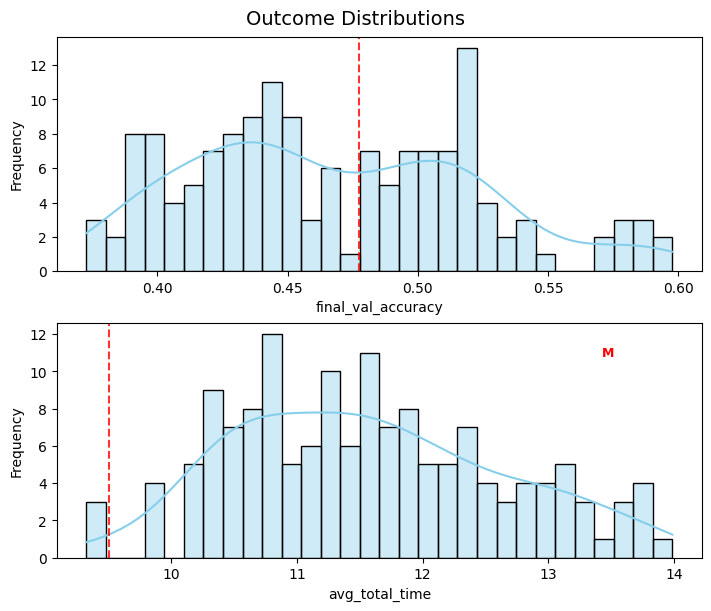

In [9]:
session.show_distributions(figsize=(7,3))
plt.show()

### How to read `S`, `M` and `L`

- **`S`, `M`, `L` = small, medium, large value**, not good or bad. Whether a value is good depends on the objective's direction: for `final_val_accuracy` (maximize) `L` is best; for `avg_total_time` (minimize) `S` is best.
- **Labels are relative**, to the full compact campaign because the bin edges are fixed campaign-wide. An `L` accuracy means "among the highest in these runs", not a good accuracy in absolute terms.
- **Padding.** The fixed edges are detected on the complete compact campaign, not re-estimated within each scenario. Some outer regions can therefore be empty in a particular client-count/task view.
- **Clusters.** A histogram with several modes usually reflects a factor that shifts the objective, such as the task or the number of clients. When an edge cuts through a cluster, small differences between replications can change a run's bin. Read "a pattern moves runs up a bin" with care, and check whether runs of one configuration land in several regions.

> **Tip.** To cut an objective at meaningful limits instead of equal widths, keep the shared `TRADEOFF_EDGES` unchanged when comparing the six scenario notebooks.

We map the runs onto the objective space, with the bin edges drawn as a grid, to see the shape and density of the tradeoff regions.

In [10]:
tradeoff_labels = [t.name for t in tradeoffs]
tradeoff_labels

['S-S', 'S-M', 'S-L', 'M-S', 'M-M', 'M-L', 'L-S', 'L-M', 'L-L']

In [11]:
session.get_decisions()

{'client_selector_pattern': Decision(description='Pattern for selecting which clients participate in training', policies={'OFF': PatternPolicy(description='Client selector pattern disabled - all clients participate', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={})), 'ON': PatternPolicy(description='Client selector pattern enabled - Resource-Based selection', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={'Client Selector Strategy': 'Resource-Based', 'Client Selector Criteria': 'CPU', 'Client Selector Value': 2.0}))}),
 'message_compressor_pattern': Decision(description='Pattern for compressing messages exchanged between clients and server', policies={'OFF': PatternPolicy(description='Message compressor disabled', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={})), 'ON': PatternPolicy(description='Message compressor enabled - zlib compression', parameter_bindings=ParameterBindings(levers={}

In [12]:
session.get_policies()

{'OFF,OFF,OFF': SystemConfiguration(name='Baseline (all patterns off)', description='No architectural patterns enabled.', pattern_policy_references=[PatternPolicyReference(component='fl_system', decision='client_selector_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='message_compressor_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='hdh_pattern', policy='OFF')], source_file=None, component_policies={}),
 'ON,OFF,OFF': SystemConfiguration(name='Client selector only', description='Resource-based client selection enabled.', pattern_policy_references=[PatternPolicyReference(component='fl_system', decision='client_selector_pattern', policy='ON'), PatternPolicyReference(component='fl_system', decision='message_compressor_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='hdh_pattern', policy='OFF')], source_file=None, component_policies={}),
 'OFF,ON,OFF': SystemConfiguration(name='Message compre

### Decisions, policies and configurations

The two cells above list the same design space at two levels:

| Term | What it is | In this system | Where to see it |
|:---|:---|:---|:---|
| **Decision** | a design choice point for one pattern | `client_selector_pattern`, `message_compressor_pattern`, `hdh_pattern` | `get_decisions()` |
| **Policy** | one option of a decision; it binds values to constraint parameters | `ON` or `OFF` for each decision | `get_decisions()[d].policies` |
| **Configuration** | one policy per decision, i.e. a full system variant | e.g. `OFF,OFF,OFF` (baseline), `ON,OFF,ON` | `get_policies()`, column `config_id` |

Note that `get_policies()` returns **configurations** (ADEPT calls them system-level policies). Robustness results (Sections 6 and 11) are reported per configuration by default; pass `by='decision'` to report per decision policy instead (e.g. `hdh_pattern:ON`), or `by=<column>` to group by a run attribute (Section 7 groups by pattern stress).

#### What else the model contains

| Element | Role | Examples |
|:---|:---|:---|
| **Levers** | design settings controlled by the architect | `Model`, `Total Clients`, rounds, learning rate |
| **Constraints** | the settings a pattern's `ON` policy fixes; empty when the pattern is OFF, which ADEPT encodes as a separate "not selected" value | `Client Selector Value`, `HDH Latent Dim` |
| **Uncertainties** | conditions the architect does not control | shares of low-spec, non-IID and delayed clients; client CPU/RAM; data heterogeneity |
| **Quality objectives** | measured outcomes of each run | `final_val_accuracy` and `avg_total_time` are analyzed; the others stay in the spec |

All three parameter kinds are candidate *explanations* of the objectives: Section 8 scores how much each one matters, and Sections 9-10 describe tradeoff regions as ranges over the top-ranked ones.

Saved objective-space chart: plots/quality-space__task-image__hdh-only_OFF_OFF_ON__clients-all__environment-all__final_val_accuracy-vs-avg_total_time.png


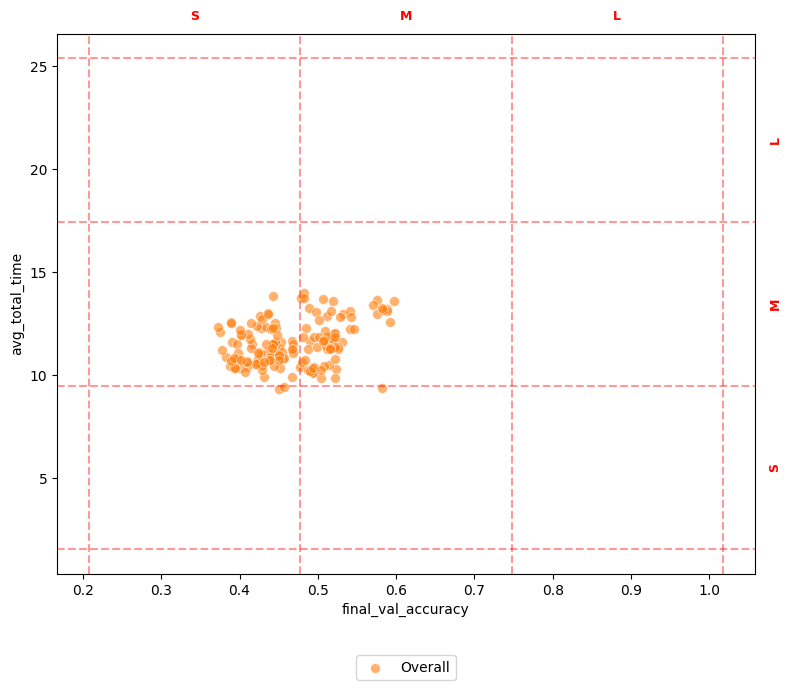

In [13]:
outcome_cols = list(TRADEOFF_LABELS)
# Plot the policies for all combinations (pairs) of quality objectives
for x_col, y_col in itertools.combinations(outcome_cols, 2):
    fig = session.show_quality_objective_space(
        x_col, y_col,
        # highlight_tradeoffs=[session.get_tradeoff(tradeoffs[7].name)],
        # show_overall=True,
        subset='all',
        show_overall=True,
        overall_color=PLOT_COLOR,
        alpha=1.0,
        figsize=(8, 7),
        s=50,
        title=""
    )
    # fig.savefig(f'fl-quality_objective_space_{x_col}_{y_col}.png', dpi=500)
    chart_path = PLOT_DIR / f'{PLOT_STEM}__{x_col}-vs-{y_col}.png'
    fig.savefig(chart_path, dpi=300, bbox_inches='tight')
    print(f'Saved objective-space chart: {chart_path}')
    plt.show()

### Reading the objective space

- **Points and colors.** Each point is one run, colored by its configuration.
- **Grid.** The dashed lines are the bin edges, so each grid cell is one tradeoff region: columns are the accuracy bin (`S`, `M`, `L` from left to right), rows the time bin (`S`, `M`, `L` from bottom to top). The ideal region `L-S` is the bottom-right cell.
- **What to look for:**
  - clusters of runs, which usually correspond to a factor such as the task or the number of clients;
  - whether the runs of one configuration stay in one region or straddle an edge;
  - which configurations reach the high-accuracy column, and at what time cost.

## 5. Contingency Analysis: Composite and Marginal Decisions

Contingency counts how the runs of each policy group spread over the tradeoff regions. In a multi-pattern system, "policy" can mean two things, selected with the `by` argument:

- **Composite decisions** (`by='configuration'`, the default): one row per configuration, i.e. per combination of the three pattern policies (`OFF,ON,ON`, ...). This is what an architect actually deploys, and it is the faithful view of a multi-pattern system.
- **Marginal decisions** (`by='<decision>'` or `by='decision'` for all of them): one row per policy of one pattern. A marginal row pools every configuration with that policy, weighted by its runs, so it describes the pattern *on average over the other decisions as they were sampled*.

From each table we list:

- **deterministic groups**: groups whose runs all fall in a single region;
- **exclusive tradeoffs**: regions reached by only one group of the grouping (for `by='decision'`, within each decision).

Marginal results mix configurations and conditions. Use the complete-configuration tables for deployable alternatives; marginal rows are descriptive summaries only. This single-pattern notebook contains only `OFF,OFF,ON`; the tables describe that policy and cannot contrast it with baseline or another pattern configuration.

Only decisions with more than one policy in the loaded runs are analyzed marginally. When no decision varies (a slice with a single configuration), the spread of the runs comes from the context, so the runs are grouped by the context factors that vary instead: client count, model (task) and environment.

In [14]:
# Groupings for the contingency analysis: composite decisions (configurations) first,
# then the marginal view of each decision that varies in these runs. Without varying
# decisions, group by the context factors that vary instead.
varying_decisions = session.get_varying_decisions()
CONTEXT_COLUMNS = ['Total Clients', 'Model', *fl_slices.ENVIRONMENT_COLUMNS]
context_groupings = [c for c in CONTEXT_COLUMNS
                     if c in session.experiments_df.columns and session.experiments_df[c].nunique() > 1]

contingency_groupings = ['configuration'] + (varying_decisions or context_groupings)
print("Decisions that vary in these runs:", varying_decisions or "none")
if not varying_decisions:
    print("Context factors that vary:", context_groupings or "none")
print("Contingency groupings:", contingency_groupings)

Decisions that vary in these runs: none
Context factors that vary: ['Total Clients', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']
Contingency groupings: ['configuration', 'Total Clients', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']


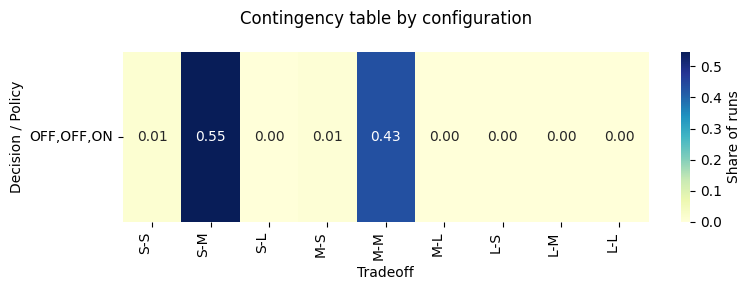

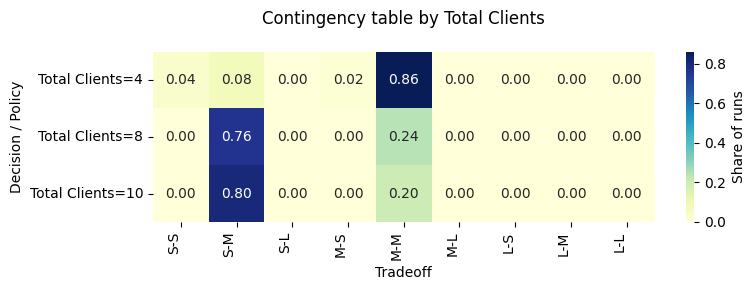

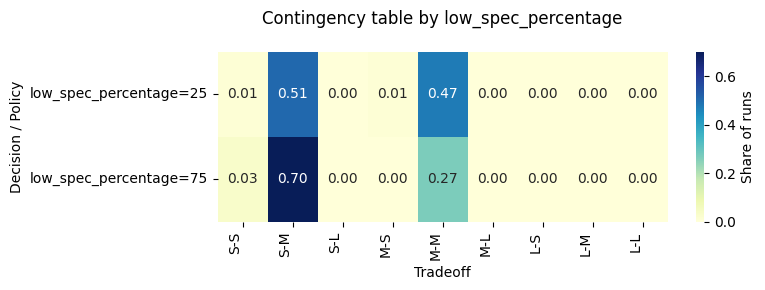

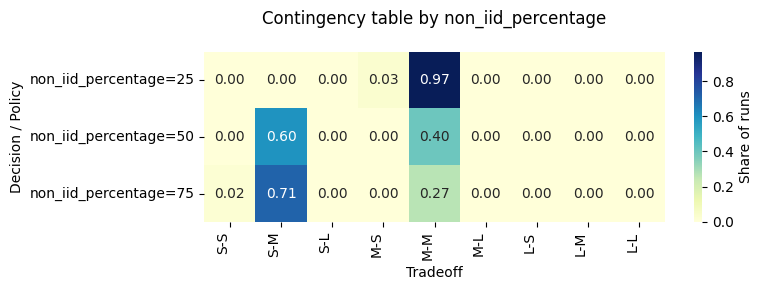

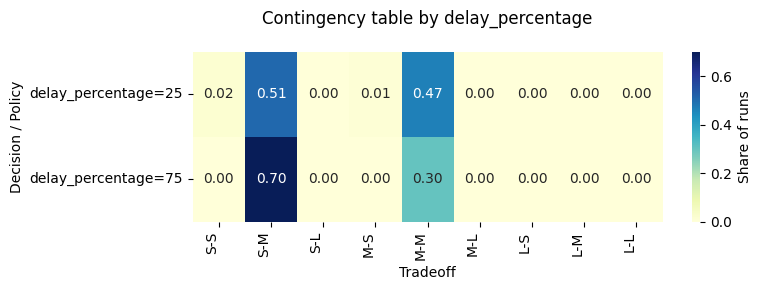

In [15]:
for by in contingency_groupings:
    n_rows = len(session.get_policy_contingency_matrix(by=by))
    session.show_policy_contingency(
        by=by,
        type='heatmap',
        subset='all',
        title=f"Contingency table by {by}",
        figsize=(8, max(3, 0.45 * n_rows + 1.5))
    )
    plt.show()

In [16]:
print("Deterministic groups (all their runs fall in a single tradeoff)")
for by in contingency_groupings:
    print("---" * 10)
    print("Grouping:", by)
    pairs = session.get_deterministic_policies(by=by)
    for policy, tradeoff in pairs:
        print("* Group:", policy, "--> Tradeoff:", tradeoff)
    if not pairs:
        print("  none")

Deterministic groups (all their runs fall in a single tradeoff)
------------------------------
Grouping: configuration
  none
------------------------------
Grouping: Total Clients
  none
------------------------------
Grouping: low_spec_percentage
  none
------------------------------
Grouping: non_iid_percentage
  none
------------------------------
Grouping: delay_percentage
  none


In [17]:
print("Exclusive tradeoffs (reached by a single group of the grouping)")
for by in contingency_groupings:
    print("---" * 10)
    print("Grouping:", by)
    pairs = session.get_exclusive_tradeoffs(by=by)
    for policy, tradeoff in pairs:
        print("* Tradeoff:", tradeoff, "--> Group:", policy)
    if not pairs:
        print("  none")

Exclusive tradeoffs (reached by a single group of the grouping)
------------------------------
Grouping: configuration
  none
------------------------------
Grouping: Total Clients
* Tradeoff: S-S --> Group: Total Clients=4
* Tradeoff: M-S --> Group: Total Clients=4
------------------------------
Grouping: low_spec_percentage
* Tradeoff: M-S --> Group: low_spec_percentage=25
------------------------------
Grouping: non_iid_percentage
* Tradeoff: S-S --> Group: non_iid_percentage=75
* Tradeoff: M-S --> Group: non_iid_percentage=25
------------------------------
Grouping: delay_percentage
* Tradeoff: S-S --> Group: delay_percentage=25
* Tradeoff: M-S --> Group: delay_percentage=25


### Reading the contingency results

- **Start with the composite view.** A deterministic configuration always leads to one region; an exclusive region is reached by one configuration only.
- **Marginal results are mixtures.** A deterministic marginal policy means that *every* configuration with that policy reaches the same region, a strong claim. The absence of a deterministic marginal policy says nothing about the configurations themselves.
- **Marginal exclusivity is not attribution.** A region reached only by configurations that share two `ON` policies (for example `ON,OFF,ON` and `ON,ON,ON`) is reported as exclusive to *both* policies in the marginal view. Check the composite table to see which combination reaches it. These summaries describe co-occurrence and should not be interpreted as isolated pattern effects.
- **Unequal weights.** If the configurations of a marginal row have different numbers of runs, the row leans toward the larger ones.
- **Context grouping** (single-configuration slices) shows what drives the spread when no pattern varies: client count, task or environment. It is not a pattern effect.
- **Exclusivity needs at least two groups.** With a single group, every reached region would be trivially exclusive, so ADEPT reports none and prints a warning.

## 6. Robustness Analysis (Quantifying Stability)

Contingency (Section 5) describes *where* the runs of each policy group land. Robustness takes one target tradeoff at a time and asks how reliably each group reaches it, and how badly it misses when it does not:

- **STARR (success rate)**: the share of a group's runs that fall in the target region. Higher is better.
- **REGRET (risk)**: for each run, the distance from its objective values to the bounds of the target region, with each objective divided by its standard deviation (0 for runs inside the region). A group's regret is the mean over its runs. Lower is better.

The robustness matrix and heatmap use the test runs, the runs on which the boxes are evaluated later (Section 11); the ranking below uses all runs.

In [18]:
metric = 'starr' #'starr' 'regret'

In [19]:
base_robustness_matrix = session.get_robustness_report(metric=metric, subset='test') 
base_robustness_matrix # Test

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
policy,,,,,,,,,
"OFF,OFF,ON",0.0,0.555556,0.0,0.0,0.444444,0.0,0.0,0.0,0.0


Robustness Ranking for Tradeoff: S-S
  1. OFF,OFF,ON: 1% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0133 - Regret: 1.9766
Robustness Ranking for Tradeoff: S-M
  1. OFF,OFF,ON: 55% success
  Top Policy -> OFF,OFF,ON - Starr: 0.5467 - Regret: 0.3580
Robustness Ranking for Tradeoff: S-L
  1. OFF,OFF,ON: 0% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0000 - Regret: 5.4432
Robustness Ranking for Tradeoff: M-S
  1. OFF,OFF,ON: 1% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0067 - Regret: 2.0766
Robustness Ranking for Tradeoff: M-M
  1. OFF,OFF,ON: 43% success
  Top Policy -> OFF,OFF,ON - Starr: 0.4333 - Regret: 0.5413
Robustness Ranking for Tradeoff: M-L
  1. OFF,OFF,ON: 0% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0000 - Regret: 5.4523
Robustness Ranking for Tradeoff: L-S
  1. OFF,OFF,ON: 0% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0000 - Regret: 5.7596
Robustness Ranking for Tradeoff: L-M
  1. OFF,OFF,ON: 0% success
  Top Policy -> OFF,OFF,ON - Starr: 0.0000 - Regret: 5.328

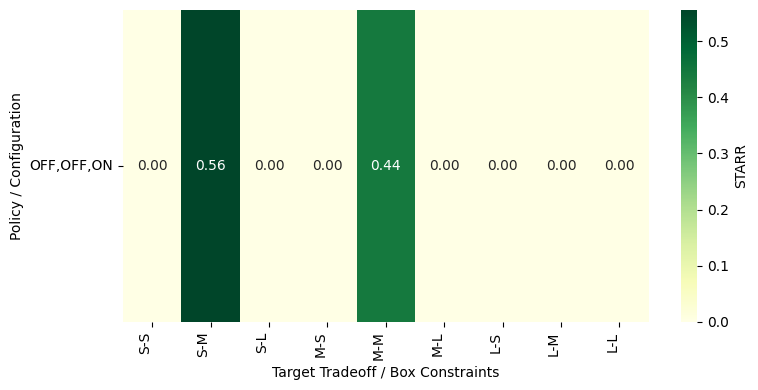

In [20]:
for tradeoff in session.get_tradeoffs():
    print(f"Robustness Ranking for Tradeoff: {tradeoff.name}")
    ranking = session.get_policy_robustness_ranking(tradeoff.name, metric='starr')
    for i, (pol, val) in enumerate(ranking[:3]):
        print(f"  {i+1}. {pol}: {val:.0%} success")
    
    if ranking:
        top_pol = ranking[0][0]
        starr = session.compute_robustness(top_pol, tradeoff.name, metric='starr')
        regret = session.compute_robustness(top_pol, tradeoff.name, metric='regret')
        print(f"  Top Policy -> {top_pol} - Starr: {starr.get('value', 0.0):.4f} - Regret: {regret.get('value', 0.0):.4f}")

if metric == 'starr':
    print("Overall Robustness Heatmap (STARR):")
    session.show_robustness_heatmap(matrix=base_robustness_matrix, metric='starr', figsize=(8,4))
    plt.show()

if metric == 'regret':
    print("Overall Robustness Heatmap (REGRET):")
    session.show_robustness_heatmap(matrix=base_robustness_matrix, metric='regret', figsize=(8,4), title=metric)
    plt.show()

### How robustness relates to contingency

- **STARR is a contingency share.** For a group *g* and a region *T*, STARR(*g*, *T*) is the share of *g*'s runs in *T*: the cell (*g*, *T*) of the contingency table with `normalization_mode='population'` (the default). On the same runs the two tables hold the same numbers; here they differ only because Section 5 uses all runs and the robustness matrix the held-out seed groups.
- **The question changes.** Contingency reads a *row*: how one group spreads over all regions. Robustness reads a *column*: for one target region, which group reaches it most reliably (the ranking). STARR is also the baseline that Section 11 compares with the success rate inside the boxes.
- **REGRET adds what contingency cannot show: how far the misses are.** Groups with the same STARR can be very different choices.

Example (illustrative values), target `L-S` (high accuracy, fast):

| Group | Runs in `L-S` | Where its other runs are | STARR | REGRET |
|:---|:---|:---|---:|:---|
| A | 5 of 10 | `M-S`, just below the accuracy edge | 0.50 | low |
| B | 5 of 10 | `S-L`, far below in accuracy and much slower | 0.50 | high |
| C | 9 of 10 | one run in `S-L` | 0.90 | medium: one large miss averaged over 10 runs |

A and B have the same contingency share and STARR, but A nearly meets the target when it misses: it is the more robust choice. C shows that mean regret mixes how often and how far a group misses, so read it together with STARR.

- **Units.** Regret is in standard deviations of each objective over the loaded runs: comparable across groups and regions of one notebook, not across notebooks.

## 7. Pattern Stress

**Pattern stress** measures how much patterning a run carries (`pattern_stress.py`):

- **`Pattern Instances`** (S_inst), the **primary measure**: how many pattern instances are deployed, summed over the patterns. The same pattern type can have several instances, so S_inst captures the size of the deployment; it depends on the configuration, on the client environment and on the other decisions (the client selector removes clients, and their compressor and HDH instances with them). It is declared as an uncertainty, so boxes on it read as conditional prescriptions.
- **`Pattern Types Active`** (S_types, 0-3), a secondary measure: how many of the three pattern decisions are ON. It is exact (read from the configuration) and set by the architect, so it is declared as a lever.

How the instances are counted:

| Pattern | Count | Source |
|:---|:---|:---|
| client selector | 1 when ON | assumption A1 (not recorded) |
| message compressor | 1 per participating client | assumption A2 (not recorded) |
| HDH | participating clients that did HDH work (`HDH Time > 0`) | **measured** from the per-round data in `detailed/` when available (the load message says so); otherwise assumption A3, one per participating non-IID client |

The measured HDH count matters for the image task, where HDH almost never does any work, so the A3 count would overstate it. The assumptions, the evidence and the open questions are in `compact/README.md`.

Stress levels are **mixtures of configurations**: a stress-level share is a weighted average of the configurations at that level, so read it next to the per-configuration table. Only HDH is enabled in this notebook, so `Pattern Types Active` is fixed at one. `Pattern Instances` can still vary with client participation and operating conditions; interpret its associations within this single policy and the observed all-environment mix. They do not compare alternative policies.

This section needs a spec that declares the stress parameters (`./compact/FLsystem_compact_all.json`); with other specs it is skipped. Only the measures that vary in the loaded runs are analyzed:

| Notebook | `Pattern Types Active` | `Pattern Instances` | What Section 7 shows |
|:---|:---|:---|:---|
| overview, stress notebooks | varies (0-3) | varies | everything: levels, instances, boxes |
| one pattern alone | constant (1) | varies with the environment | how the size of that pattern's deployment relates to the objectives. These notebooks mix client counts and tasks, so the count partly stands for them: compressor instances equal the participating clients, and measured HDH instances are 0 in image runs |
| baseline | constant (0) | constant (0) | nothing to compare: the tables confirm that no pattern is deployed |

In [21]:
STRESS_TYPES, STRESS_INSTANCES = 'Pattern Types Active', 'Pattern Instances'
has_stress = all(c in session.experiments_df.columns for c in (STRESS_TYPES, STRESS_INSTANCES))
objectives = list(TRADEOFF_LABELS)

if not has_stress:
    print("This spec does not declare the pattern-stress parameters "
          "(use './compact/FLsystem_compact_all.json'); Section 7 is skipped.")
    varying_stress = []
else:
    # Only stress measures that vary in these runs can be compared: in a single-configuration
    # slice S_types is constant, and in the baseline both measures are 0.
    varying_stress = [c for c in (STRESS_TYPES, STRESS_INSTANCES) if session.experiments_df[c].nunique() > 1]
    for c in (STRESS_TYPES, STRESS_INSTANCES):
        values = sorted(session.experiments_df[c].unique())
        print(f"{c}: {'varies' if c in varying_stress else 'constant'} in these runs, values {values}")

    config_col = session.sys_def.dataspace.configuration_identification.column
    stress_view = session.raw_df.assign(tradeoff=session.discrete_df.astype(str).agg('-'.join, axis=1))
    stress_view['Pattern Count Group'] = stress_view[STRESS_TYPES].map(lambda n: '0' if n == 0 else ('1' if n == 1 else '2-3'))
    by_level = stress_view.groupby(STRESS_TYPES).agg(
        runs=(config_col, 'size'), configurations=(config_col, 'nunique'),
        instances_min=(STRESS_INSTANCES, 'min'), instances_max=(STRESS_INSTANCES, 'max'),
        **{f"{o} (mean)": (o, 'mean') for o in objectives},
    )
    by_config = stress_view.groupby([STRESS_TYPES, config_col]).agg(
        runs=(config_col, 'size'), instances=(STRESS_INSTANCES, 'mean'),
        **{f"{o} (mean)": (o, 'mean') for o in objectives},
    )
    print("Per stress level (S_types):")
    display(by_level.round(3))
    print("Per configuration:")
    display(by_config.round(3))

Pattern Types Active: constant in these runs, values [1]
Pattern Instances: varies in these runs, values [0, 1, 2]
Per stress level (S_types):


,runs,configurations,instances_min,instances_max,final_val_accuracy (mean),avg_total_time (mean)
Pattern Types Active,,,,,,
1,150,1,0,2,0.468,11.56


Per configuration:


,,runs,instances,final_val_accuracy (mean),avg_total_time (mean)
Pattern Types Active,config_id,,,,
1,"OFF,OFF,ON",150,0.147,0.468,11.56


,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
policy,,,,,,,,,
Pattern Instances=0,0.02,0.58,0.0,0.01,0.39,0.0,0.0,0.0,0.0
Pattern Instances=1,0.00,0.29,0.0,0.00,0.71,0.0,0.0,0.0,0.0
Pattern Instances=2,0.00,0.25,0.0,0.00,0.75,0.0,0.0,0.0,0.0


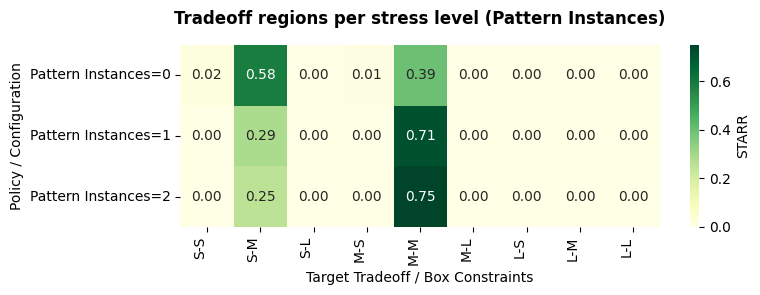

Pattern Types Active is constant in these runs: no stress levels to compare.
Counts by pattern-count group:


tradeoff,M-M,M-S,S-M,S-S
Pattern Count Group,,,,
1,65,1,82,2


Within-group tradeoff shares:


tradeoff,M-M,M-S,S-M,S-S
Pattern Count Group,,,,
1,43.3%,0.7%,54.7%,1.3%


In [22]:
# Share of each stress level's runs in every tradeoff region (STARR, all runs): by the number
# of pattern instances (primary measure), then by the number of pattern types.
# Grouping by a column: rows are '<column>=<level>' (docs/robustness_policy_grouping.md).
for stress_measure in (STRESS_INSTANCES, STRESS_TYPES):
    if stress_measure in varying_stress:
        stress_matrix = session.get_robustness_report(metric='starr', subset='all', by=stress_measure)
        display(stress_matrix.round(2))
        session.show_robustness_heatmap(matrix=stress_matrix, metric='starr',
                                        figsize=(8, 0.35 * len(stress_matrix) + 2),
                                        title=f"Tradeoff regions per stress level ({stress_measure})")
        plt.show()
    elif has_stress:
        print(f"{stress_measure} is constant in these runs: no stress levels to compare.")
# RQ1 summary in the planned 0 / 1 / 2-3 pattern-count groups.
count_table = pd.crosstab(stress_view['Pattern Count Group'], stress_view['tradeoff'])
share_table = count_table.div(count_table.sum(axis=1), axis=0)
print('Counts by pattern-count group:'); display(count_table)
print('Within-group tradeoff shares:'); display(share_table.style.format('{:.1%}'))


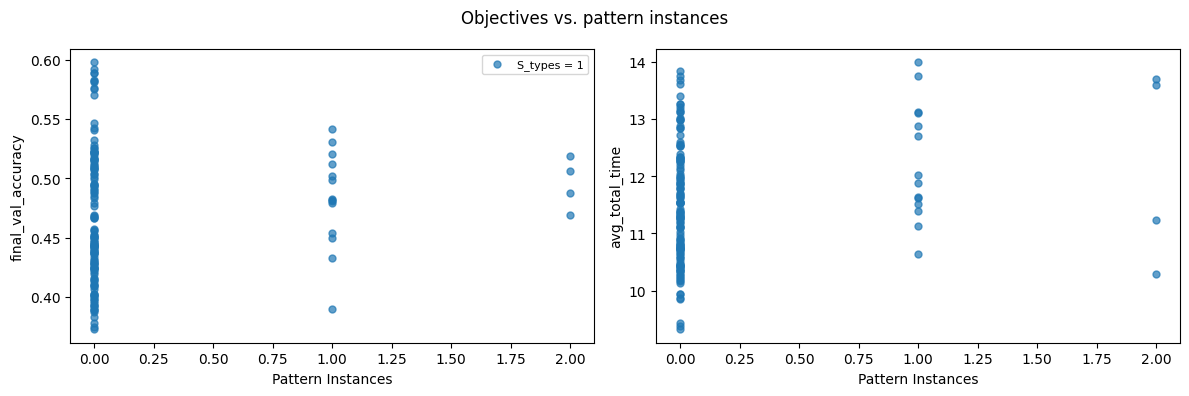

In [23]:
# Objectives against the number of pattern instances (S_inst), colored by S_types
if STRESS_INSTANCES in varying_stress:
    fig, axes = plt.subplots(1, len(objectives), figsize=(6 * len(objectives), 4), squeeze=False)
    for ax, objective in zip(axes[0], objectives):
        for level, group in stress_view.groupby(STRESS_TYPES):
            ax.scatter(group[STRESS_INSTANCES], group[objective], s=25, alpha=0.7, label=f"S_types = {level}")
        ax.set_xlabel(STRESS_INSTANCES)
        ax.set_ylabel(objective)
    axes[0][0].legend(fontsize=8)
    fig.suptitle("Objectives vs. pattern instances")
    plt.tight_layout()
    plt.show()
elif has_stress:
    print(f"{STRESS_INSTANCES} is constant in these runs: nothing to plot.")

### How to read the pattern-instance charts and tables

In **Objectives vs. pattern instances**, each dot is one experiment run. The horizontal position is its estimated total number of deployed pattern instances (`Pattern Instances`); the vertical position is one objective. The two panels show final validation accuracy (higher is better) and average total round time (lower is better). Dot color gives the number of active pattern types: 0, 1, 2, or 3. Dots at the same instance count can overlap, so the visible number of marks is not necessarily the number of runs.

Read the chart as a map of observed outcomes: within one color, compare runs with different instance counts; across colors, compare the different pattern-type groups. If points move toward lower accuracy or longer time as instance count changes, that is an association in these runs, not a prediction that adding an instance will cause that change. Same-color dots may still use different patterns, and both instance count and outcomes can vary with task, client count, environment, and configuration. The common-environment block holds task, client count and sampled environment point constant; the all-environment block shows how the same relationships vary across the campaign envelope.

`Pattern Instances` is a deployment-size estimate, not a direct architecture knob: the client selector changes how many clients participate, and compressor/HDH instance counts depend on participating clients. Some counts are inferred using assumptions A1–A2; HDH uses per-round activity data when available and a fallback rule otherwise. Confirm the count semantics before treating the horizontal axis as measured work.

- The **per-level table** gives the run count, number of configurations, instance range, and mean objectives for each number of active pattern types. Level 0 is baseline alone; levels 1 and 2 combine several configurations. Use the **per-configuration table** to see whether a group mean is driven by one alternative.
- **STARR by level** shows the share of runs in each accuracy/time region at each instance/type level. Check the run counts: rare instance levels can produce unstable shares. The stress notebooks use one task, client count, and common environment; overview-level differences can also reflect changing workload and environment mix.
- The PRIM boxes below identify regions of the observed design space. A bound on active pattern types refers to a configuration choice; a bound on estimated instances or environmental conditions describes when a tradeoff was observed. Use box support, density, and coverage before applying it to a design. These boxes and charts describe where outcomes occurred; they do not establish causal effects.

## Research Question 2 — Which conditions identify HDH-only tradeoffs, and how robust are they?

PRIM and CART describe combinations of observed run context and environmental conditions associated with each populated tradeoff region for `OFF,OFF,ON`. Their held-out what-if tables compare the target frequency before and within each box, together with retained support and coverage. Because only one pattern configuration is present, any box explanation concerns its operating envelope and run context, not a comparison with baseline or another pattern policy.


## 8. Feature Importance & Key-Parameter Selection

The notebook fits a random-forest regressor to each objective's training rows. `include_constraints=True` includes the optional pattern parameters alongside levers and uncertainties. Smart correlation selection first removes redundant encoded features; the score table then restores those removed rows with zero.

Read the heatmap as **relative predictive credit within this fitted model and slice**. The scores are normalized shares of training impurity reduction. They are not fractions of outcome variance explained, percentage changes in accuracy/time, sensitivity slopes, or causal effects, and they give no direction of improvement. Use the objective-space plots, grouped outcome distributions and box what-if results to see the observed direction.

- **Three meanings of zero:** a feature can be constant in this slice, removed as a correlated duplicate, or retained but unused by the forest. A zero does not establish that the associated decision or uncertainty is irrelevant outside this model/scope. The three pattern policies are fixed in this single-configuration slice; their zero or absent importance cannot be used to compare their effects.
- **Correlated representatives:** a label such as `Dataset` may stand for a task/model group, and an optional pattern parameter may stand for ON/OFF presence. The representative can change with the objective and the slice; correlation groups can also cross pattern/environment dimensions. A fixed batch size with missing values when OFF measures presence, not batch-size tuning.
- **Scope:** fixing task, client count, or environment removes that variation and redistributes the normalized scores. A higher pattern score in a restricted notebook does not imply a larger physical effect than in the overview.
- **Discovery gate:** equal objective weights order the ranking, but a parameter is selected when its score is **greater than 0.03 in either objective**. This is not a cutoff on the weighted average. A pruned or below-threshold parameter cannot appear directly in the inferred boxes; absence from a rule is therefore not evidence of no association.
- **Consistency and prediction:** a repeatable ranking under model seeds does not establish accurate prediction on unseen runs. The separate [feature-importance audit](../../../docs/fl_feature_importance_audit.md) checks all 14 notebooks, held-out predictions, correlated proxies, measurement availability, and ranking changes. Those added diagnostics are separate from this heatmap's saved training scores.

Use importance to identify dimensions to inspect. For a design decision, combine it with the observed outcome differences and the supported before/inside-box robustness comparison.

In [24]:
scores_df = session.compute_feature_scores(
    use_smart_correlation=True,
    include_constraints=True,
    subset='train'
)
scores_df

Scoring features for outcome: final_val_accuracy (on subset: train)
Original features (numerically encoded): ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Strategy', 'Client Selector Criteria', 'Client Selector Value', 'Message Compressor Alg', 'HDH Batch Size', 'HDH Beta 1', 'HDH Beta 2', 'HDH Discriminator', 'HDH Epochs', 'HDH Generator', 'HDH Learning Rate', 'HDH Latent Dim', 'HDH Optimizer', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'JSD Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Types Active', 'Pattern Instances', 'Client Selector Instances', 'Message Compressor Instances', 'HDH Instances', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']
Features selected: ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Strategy', 'Client Selector Criteria', 'Client Selector Value', 'Message Comp

Features selected: ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Strategy', 'Client Selector Criteria', 'Client Selector Value', 'Message Compressor Alg', 'HDH Batch Size', 'HDH Beta 1', 'HDH Beta 2', 'HDH Discriminator', 'HDH Epochs', 'HDH Generator', 'HDH Learning Rate', 'HDH Latent Dim', 'HDH Optimizer', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'JSD Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Types Active', 'Client Selector Instances', 'Message Compressor Instances', 'HDH Instances', 'low_spec_percentage', 'delay_percentage']


,final_val_accuracy,avg_total_time
Alpha Dirichlet Mean,0.086181,0.020211
Batch Size,0.000000,0.000000
CPU Mean,0.005112,0.025760
Client Selector Criteria,0.000000,0.000000
Client Selector Instances,0.000000,0.000000
Client Selector Strategy,0.000000,0.000000
Client Selector Value,0.000000,0.000000
Data Distribution Diversity,0.000000,0.000000
Data Persistence Diversity,0.000000,0.000000
Dataset,0.000000,0.000000


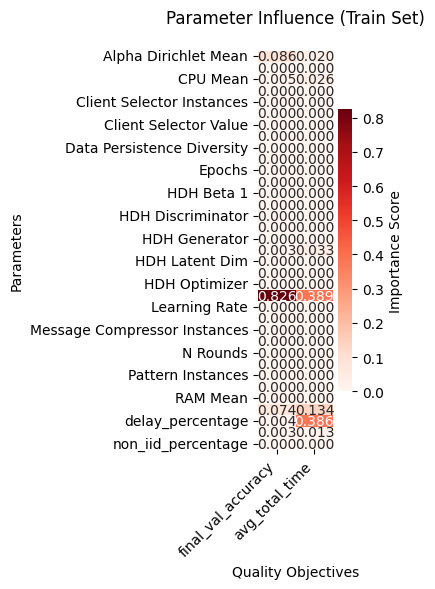

In [25]:
session.show_feature_heatmap(scores_df, title="Parameter Influence (Train Set)", figsize=(4,6))
plt.show()

### Pattern-parameter presence check

All 13 declared pattern parameters must occur as rows in the score table. This catches accidental exclusion through `include_constraints=False`. It verifies that they were offered to scoring; it does not guarantee that they survived correlation pruning, received positive importance, or passed the scenario-discovery gate. Review the selected key-parameter list before interpreting a box as a prescription for a particular pattern.

In [26]:
FL_PATTERN_PARAMETERS = [
    "Client Selector Strategy", "Client Selector Criteria", "Client Selector Value",
    "Message Compressor Alg",
    "HDH Batch Size", "HDH Beta 1", "HDH Beta 2", "HDH Discriminator", "HDH Epochs",
    "HDH Generator", "HDH Learning Rate", "HDH Latent Dim", "HDH Optimizer",
]
assert len(FL_PATTERN_PARAMETERS) == 13

missing = [p for p in FL_PATTERN_PARAMETERS if p not in scores_df.index]
assert not missing, (
    f"compute_feature_scores(include_constraints=True) dropped pattern parameters: {missing}"
)
print(f"All {len(FL_PATTERN_PARAMETERS)} FL pattern parameters are present "
      f"in the feature-importance ranking (R6 verified).")

All 13 FL pattern parameters are present in the feature-importance ranking (R6 verified).


In [27]:
weighted_features = session.get_weighted_feature_ranking(scores_df)
print("Weighted feature ranking:", weighted_features)

# Categorical parameters (e.g. Model) and optional ones (NaN = pattern not selected)
# are encoded numerically by ADEPT, so every ranked parameter can go to discovery.
# A low threshold (0.03) keeps the pattern parameters with a secondary influence next
# to a dominant factor.
key_parameters = session.select_top_k_parameters(
    scores_df, index_order=weighted_features, threshold=0.03, k=None
)
print("Key parameters (for scenario discovery):", key_parameters)

Weighted feature ranking: ['JSD Mean', 'delay_percentage', 'Total Clients', 'Alpha Dirichlet Mean', 'HDH Instances', 'CPU Mean', 'low_spec_percentage']
Key parameters (for scenario discovery): ['JSD Mean', 'delay_percentage', 'Total Clients', 'Alpha Dirichlet Mean', 'HDH Instances']


## 9. Scenario Discovery: PRIM

PRIM searches for parameter boxes associated with non-empty tradeoff regions. `readable_limits()` decodes each condition. Section 10.1 adds a specification-only trace that groups the joint conditions through declared policies and parameter roles; it does not change the learned box or its metrics.

In [28]:
# Scenario discovery uses the key parameters selected in Section 8 (threshold=0.03).
print("Key parameters (for scenario discovery):", key_parameters)

Key parameters (for scenario discovery): ['JSD Mean', 'delay_percentage', 'Total Clients', 'Alpha Dirichlet Mean', 'HDH Instances']


In [29]:
prim_boxes = []
non_empty_tradeoffs = session.get_tradeoffs(non_empty=True)
for tradeoff in non_empty_tradeoffs:
    print("---" * 10)
    print(f"Discovering scenarios for: {tradeoff.name}")
    boxes = session.discover_scenarios(
        tradeoff.name, method='prim',
        threshold=0.8,
        standardize=True,
        parameters=key_parameters
    )
    non_empty_boxes = [b for b in boxes if not b.is_empty()]
    if non_empty_boxes:
        best_box = non_empty_boxes[0]
        print(f"* Key Rules: {best_box.describe_limits(digits=3)}")
        print(f"* Metrics: {best_box.metrics}")
        prim_boxes.append(best_box)
    else:
        print("--> No scenarios discovered.")

print(f"\n{len(prim_boxes)} non-empty PRIM box(es) discovered across "
      f"{len(non_empty_tradeoffs)} non-empty tradeoffs.")

------------------------------
Discovering scenarios for: S-S
Running PRIM discovery for: S-S ...
Instances satisfying property: False    103
True       2
Name: count, dtype: int64
Total instances: (105, 5)
Running PRIM ... rhodium
2 possible boxes
--> No scenarios discovered.
------------------------------
Discovering scenarios for: S-M
Running PRIM discovery for: S-M ...
Instances satisfying property: True     57
False    48
Name: count, dtype: int64
Total instances: (105, 5)
Running PRIM ... rhodium
5 possible boxes
* Key Rules: {'Total Clients': '[6.000, 10.000]', 'Alpha Dirichlet Mean': '[0.600, 0.812]', 'JSD Mean': '[0.019, 0.081]'}
* Metrics: {'density': 0.95, 'coverage': 0.76, 'population_prevalence': 0.5428571428571428, 'lift': 0.40714285714285714, 'samples_in_box': 20.0, 'targets_in_box': 19.0}
------------------------------
Discovering scenarios for: M-S
Running PRIM discovery for: M-S ...
Instances satisfying property: False    104
True       1
Name: count, dtype: int64
Tot

/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perf

In [30]:
# Box rules in original values (see "Reading the rules of a box" below);
# box.readable_limits() gives the exact limits.
boxes_to_keep = []
print("Summary of PRIM boxes:")
for idx, box in enumerate(prim_boxes):
    if not box.is_empty():
        lift = box.metrics.get('lift', None)
        print(f" {idx+1}. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}): lift={lift:.2f}")
        for param, condition in box.describe_limits(digits=3).items():
            print(f"\t{param}: {condition}")
        boxes_to_keep.append(box)
    else:
        solutions = box.metrics.get('targets_in_box', 0)
        print(f" Skipping empty box. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}) {solutions}")
prim_boxes = boxes_to_keep

Summary of PRIM boxes:
 1. For tradeoff S-M (S,M): lift=0.41
	Total Clients: [6.000, 10.000]
	Alpha Dirichlet Mean: [0.600, 0.812]
	JSD Mean: [0.019, 0.081]
 2. For tradeoff M-M (M,M): lift=0.24
	Total Clients: [4.000, 6.000]
	Alpha Dirichlet Mean: [0.613, 0.900]
	JSD Mean: [0.000, 0.057]
	HDH Instances: [0.500, 2.000]


### Reading the PRIM boxes

Each box is a conjunction (**AND**) of conditions. Parameters not listed are unrestricted. The decoded rule and its density, coverage, and lift describe the original box; below, the specification context groups those same conditions through declared components, decisions, policy bindings, and parameter roles.

`(not selected)` is an encoding used for optional values. It identifies OFF only when the system specification declares that applicability relationship. A policy binding points from a policy to a setting (for example, Client Selector ON binds `Client Selector Criteria = CPU`); the explanation does not reverse that link into “CPU requires ON” unless the specification also defines the complementary state. Multiple conditions are read jointly. A lever or uncertainty remains a condition on that parameter unless an explicit policy binding connects it to a decision.

Category intervals are decoded to the category values they cover. Their category ordering is an encoding detail and does not imply similarity. Density, coverage, and support remain properties of the evaluated box, separate from the specification trace.

In [31]:
# Print prim_boxes to a JSON file
# with open('prim_boxes-fl.json', 'w') as f:
#     json_boxes = [box.model_dump() for box in prim_boxes]
#     json.dump(json_boxes, f, indent=4)


## 10. Global Discovery: CART

A decision tree partitions the entire design space into regions, giving a global map of the most likely outcome for any combination of the key parameters.

In [32]:
cart_boxes_all = session.discover_scenarios(method='cart', standardize=True, parameters=key_parameters)
cart_boxes = []
for idx, box in enumerate(cart_boxes_all):
    if not box.is_empty():
        lift = box.metrics.get('lift', None)
        lift_str = f"{lift:.2f}" if lift is not None else "n/a"
        print(f" {idx+1}. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}): lift={lift_str}")
        for param, condition in box.describe_limits(digits=3).items():
            print(f"\t{param}: {condition}")
        cart_boxes.append(box)
    else:
        solutions = box.metrics.get('targets_in_box', 0)
        print(f" Skipping empty box. For tradeoff {box.target_tradeoff} "
              f"({box.target_tradeoff_labels}) {solutions}")

print(f"\n{len(cart_boxes)} non-empty CART box(es) discovered.")

Running CART global discovery for all tradeoff combinations ...
 1. For tradeoff S-M (S,M): lift=0.41
	Total Clients: [5.999, 10.000]
	JSD Mean: [0.018, 0.081]
 2. For tradeoff M-M (M,M): lift=0.57
	JSD Mean: [0.001, 0.014]
 Skipping empty box. For tradeoff S-S (S,S) 0.0

2 non-empty CART box(es) discovered.


## 10.1 Architectural interpretation of the discovered boxes

Each box is a conjunction. The explanation groups related pattern settings under their policy and shows uncertainty conditions as the operating envelope. The compact text has one line break after the box label. Use `session.explain_box_context(box, output_format="plain")` or `output_format="markdown"`; both formats omit the redundant configuration listing. These are specification consistency descriptions, not separate or causal effects; they do not change box membership or metrics.

In [33]:
for method_name, discovered_boxes in (("PRIM", prim_boxes), ("CART", cart_boxes)):
    for box_index, box in enumerate(discovered_boxes, start=1):
        if box.is_empty():
            continue
        print(f"{method_name} Box {box_index}: {box.target_tradeoff} ({box.target_tradeoff_labels})\n{session.explain_box_context(box, output_format='plain')['text']}")


PRIM Box 1: S-M (S,M)
Architectural interpretation
• Design prescription:
  ◦ No pattern policy is required by the box conditions
• Operating envelope:
  ◦ Alpha Dirichlet Mean [0.6, 0.812]
  ◦ JSD Mean [0.0194, 0.081]
• Other design conditions:
  ◦ Total Clients [6, 10]
PRIM Box 2: M-M (M,M)
Architectural interpretation
• Design prescription:
  ◦ No pattern policy is required by the box conditions
• Operating envelope:
  ◦ Alpha Dirichlet Mean [0.613, 0.9]
  ◦ JSD Mean [0, 0.0575]
  ◦ HDH Instances [0.5, 2]
• Other design conditions:
  ◦ Total Clients [4, 6]
CART Box 1: S-M (S,M)
Architectural interpretation
• Design prescription:
  ◦ No pattern policy is required by the box conditions
• Operating envelope:
  ◦ JSD Mean [0.0181, 0.081]
• Other design conditions:
  ◦ Total Clients [6, 10]
CART Box 2: M-M (M,M)
Architectural interpretation
• Design prescription:
  ◦ No pattern policy is required by the box conditions
• Operating envelope:
  ◦ JSD Mean [0.000991, 0.0144]


### Reading the CART boxes

- **Leaves as boxes.** Each leaf's path is a conjunction of conditions associated with its predicted tradeoff label.
- **Rules.** Read decoded limits as in Section 9. Specification context is shown below for both PRIM and CART boxes.
- **Joint design meaning.** Conditions bound by the same policy are grouped together. Explicit configurations are checked against all relevant declared bindings. Missing applicability or an unbound value is reported as unspecified; it is not guessed from a parameter name or role.
- **Role matters.** A lever or uncertainty condition remains a condition on that parameter unless the JSON declares a policy binding. In particular, a non-IID range is an operating-condition constraint; it does not by itself require HDH ON.
- **CART and PRIM.** Compare their original rules and empirical box metrics separately from this specification-only context. A shared architectural trace does not add evidence about outcomes or causal effects.

In [34]:
# Print cart_boxes to a JSON file
# with open('cart_boxes-fl.json', 'w') as f:
#     json_boxes = [box.model_dump() for box in cart_boxes]
#     json.dump(json_boxes, f, indent=4)


## 11. What-if analysis: robustness after applying box rules

Scenario discovery is useful to a designer because a box can restrict the admissible design/environment space to conditions where the chosen accuracy–time tradeoff is reached more consistently. The tables compare each configuration over its unconstrained test scenarios with the subset satisfying the inferred PRIM or CART rule. Here **baseline robustness** means that configuration's unconstrained rate, including configurations with patterns ON; it does not mean the all-patterns-OFF configuration.

For configuration $d$, target $T$, and box $B$:

- **Before:** $R_0=P(T\mid d)$, the fraction of that configuration's test runs in the target region.
- **Inside the box:** $R_B=P(T\mid d,B)$, the fraction of retained runs in the target. The PRIM/CART matrices below contain these conditional rates, **not the change itself**.
- **Robustness gain:** $R_B-R_0$, reported in percentage points. Compare the baseline and box-constrained matrices for the same configuration and target.
- **Retained scenario fraction:** $P(B\mid d)$ and the retained run count describe how much operating/design freedom the rule leaves. This differs from **target coverage** $P(B\mid T,d)$, the fraction of successful target runs the rule captures. The target-coverage matrices below use the latter meaning.

For the what-if decision, read gain and support together: a rise to 100% based on two retained runs is weaker evidence than the same rate on a larger subset. A displayed zero in a box-constrained matrix can mean that **no scenarios of that configuration are retained**, since the current matrix implementation also fills unsupported cells with zero. It must not automatically be read as an observed failure rate. A `None` column means no box was discovered for that target.

A rule on a pattern decision or lever gives a candidate restriction the designer can implement. A rule on delay, non-IID share, or another uncertainty states an operating envelope: the designer can assess or require that envelope, but selecting a configuration alone does not enforce it. PRIM and CART can offer different gain-versus-retention compromises for the same target.

This what-if evaluation filters held-out observations; it does not rerun the system with changed inputs. Higher STARR demonstrates more consistent **membership in the target tradeoff** across the retained scenarios. It does not by itself demonstrate a lower standard deviation of continuous accuracy or time within that region, or a guaranteed result on a new deployment.

In [35]:
# Held-out box metrics complement the configuration-level robustness matrices below.
def heldout_box_summary(boxes, method):
    X, _, _ = session._get_subset_data('test')
    X = session._encode_for_boxes(X)
    rows = []
    for box in boxes:
        inside = pd.Series(True, index=X.index)
        for parameter, bounds in box.limits.items():
            if parameter in X.columns:
                inside &= X[parameter].between(bounds['min'], bounds['max'])
        target = pd.Series(True, index=X.index)
        definition = session.get_tradeoff(box.target_tradeoff)
        for objective, label in definition.elements.items():
            target &= session.discrete_df.loc[X.index, objective].astype(str).eq(str(label))
        base_n, target_n = len(X), int(target.sum())
        inside_n, hits = int(inside.sum()), int((inside & target).sum())
        base_rate = target_n / base_n if base_n else float('nan')
        precision = hits / inside_n if inside_n else float('nan')
        rows.append({'method': method, 'target': box.target_tradeoff,
                     'test_n': base_n, 'baseline_target_n': target_n,
                     'box_n': inside_n, 'target_in_box': hits,
                     'baseline_rate': base_rate, 'box_precision': precision,
                     'test_delta_rate': precision - base_rate if inside_n else float('nan'),
                     'train_lift_absolute': box.metrics.get('lift'),
                     'test_recall_coverage': hits / target_n if target_n else float('nan')})
    return pd.DataFrame(rows)
print('PRIM: held-out support, precision, lift and target coverage')
display(heldout_box_summary(prim_boxes, 'PRIM').round(3))
print('CART: held-out support, precision, lift and target coverage')
display(heldout_box_summary(cart_boxes, 'CART').round(3))


PRIM: held-out support, precision, lift and target coverage


,method,target,test_n,baseline_target_n,box_n,target_in_box,baseline_rate,box_precision,test_delta_rate,train_lift_absolute,test_recall_coverage
0,PRIM,S-M,45,25,20,19,0.556,0.950,0.394,0.407,0.76
1,PRIM,M-M,45,20,3,2,0.444,0.667,0.222,0.238,0.10


CART: held-out support, precision, lift and target coverage


,method,target,test_n,baseline_target_n,box_n,target_in_box,baseline_rate,box_precision,test_delta_rate,train_lift_absolute,test_recall_coverage
0,CART,S-M,45,25,20,19,0.556,0.95,0.394,0.407,0.76
1,CART,M-M,45,20,8,8,0.444,1.00,0.556,0.571,0.40


In [36]:
# Rows are policy groups. With several decisions, 'policy' is ambiguous (plain ON/OFF repeats
# across decisions), so the grouping is explicit: by='configuration' (default, one row per
# configuration such as 'OFF,OFF,ON'), by='decision' (rows like 'hdh_pattern:ON') or
# by='<decision>'. base_robustness_matrix must be computed with the same `by`.
# See docs/robustness_policy_grouping.md.
combined_df = session.get_robustness_results(prim_boxes, cart_boxes, baseline=base_robustness_matrix, by='configuration')
# combined_df.to_csv('results-fl.csv', index=False, decimal=',')
combined_df

,method,policy,target,L-L,L-M,L-S,M-L,M-M,M-S,S-L,S-M,S-S
0,test set,"OFF,OFF,ON",,0.0,0.0,0.0,0.0,0.444444,0.0,0.0,0.555556,0.0
1,prim,"OFF,OFF,ON",M-M,0.0,0.0,0.0,0.0,0.666667,0.0,0.0,0.333333,0.0
2,prim,"OFF,OFF,ON",S-M,0.0,0.0,0.0,0.0,0.050000,0.0,0.0,0.950000,0.0
3,cart,"OFF,OFF,ON",M-M,0.0,0.0,0.0,0.0,1.000000,0.0,0.0,0.000000,0.0
4,cart,"OFF,OFF,ON",S-M,0.0,0.0,0.0,0.0,0.050000,0.0,0.0,0.950000,0.0


In [37]:
prim_box_list = session.align_boxes_to_tradeoffs(prim_boxes) # PRIM

prim_robustness_improvement_matrix = session.get_policy_robustness_improvement_matrix(prim_box_list, metric=metric, subset='test')
prim_robustness_improvement_matrix

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
"OFF,OFF,ON",None,0.95,None,None,0.666667,None,None,None,None


In [38]:
session.get_tradeoff_coverage_matrix(prim_boxes, subset='test')

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
S-M,0.0,0.76,0.0,0.0,0.05,0.0,0.0,0.0,0.0
M-M,0.0,0.04,0.0,0.0,0.10,0.0,0.0,0.0,0.0


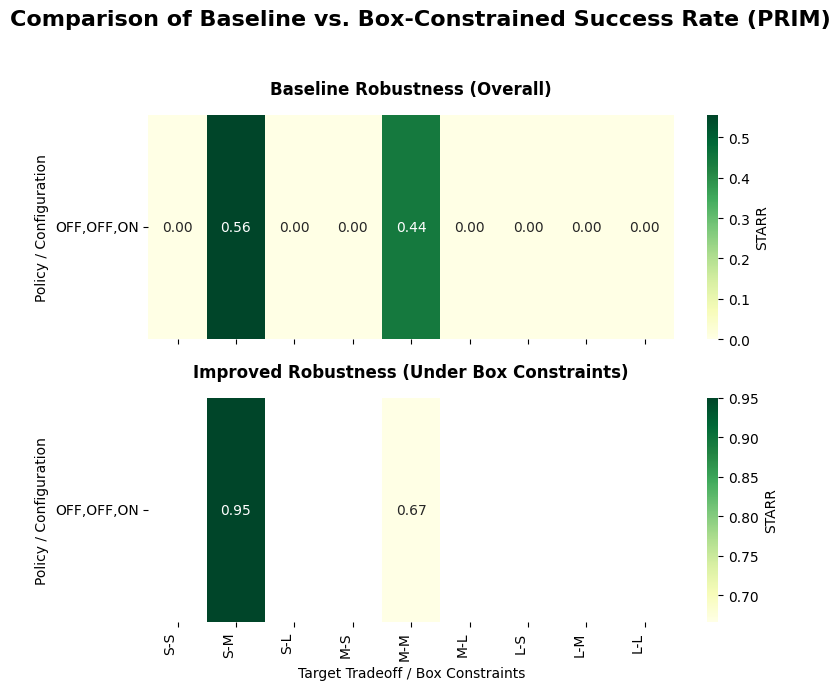

In [39]:
fig = session.show_policy_robustness_comparison_heatmap(
    baseline_matrix=base_robustness_matrix,
    improved_matrix=prim_robustness_improvement_matrix,
    boxes=prim_box_list, 
    metric=metric, 
    figsize=(8,7),
    title="Comparison of Baseline vs. Box-Constrained Success Rate (PRIM)"
)

In [40]:
cart_box_list = session.align_boxes_to_tradeoffs(cart_boxes) # CART

cart_robustness_improvement_matrix = session.get_policy_robustness_improvement_matrix(cart_box_list, metric=metric, subset='test')
cart_robustness_improvement_matrix

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
"OFF,OFF,ON",None,0.95,None,None,1.0,None,None,None,None


In [41]:
session.get_tradeoff_coverage_matrix(cart_boxes, subset='test')

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
S-M,0.0,0.76,0.0,0.0,0.05,0.0,0.0,0.0,0.0
M-M,0.0,0.00,0.0,0.0,0.40,0.0,0.0,0.0,0.0


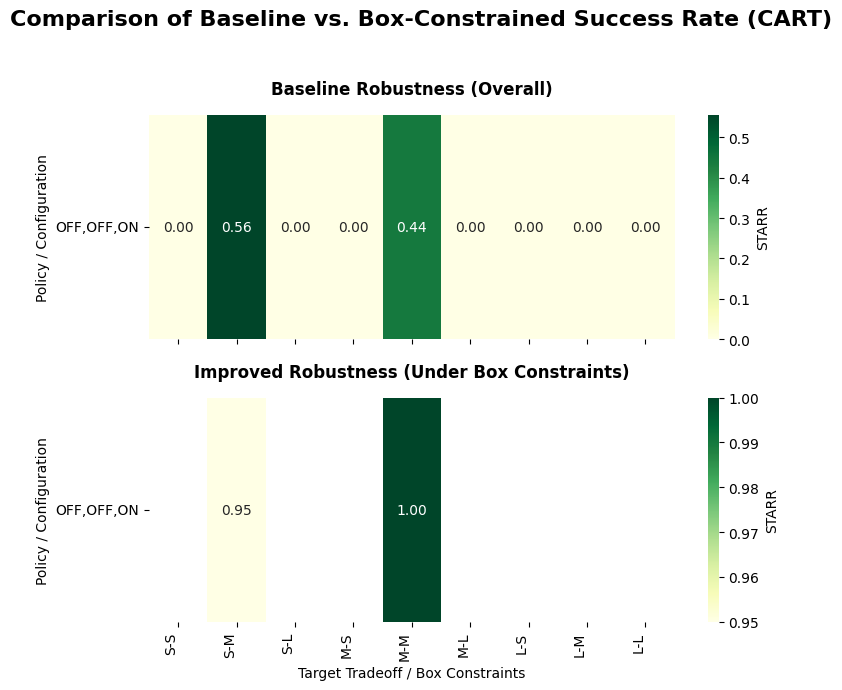

In [42]:
fig = session.show_policy_robustness_comparison_heatmap(
    baseline_matrix=base_robustness_matrix,
    improved_matrix=cart_robustness_improvement_matrix,
    boxes=cart_box_list, 
    metric=metric, 
    figsize=(8,7),
    title="Comparison of Baseline vs. Box-Constrained Success Rate (CART)"
)

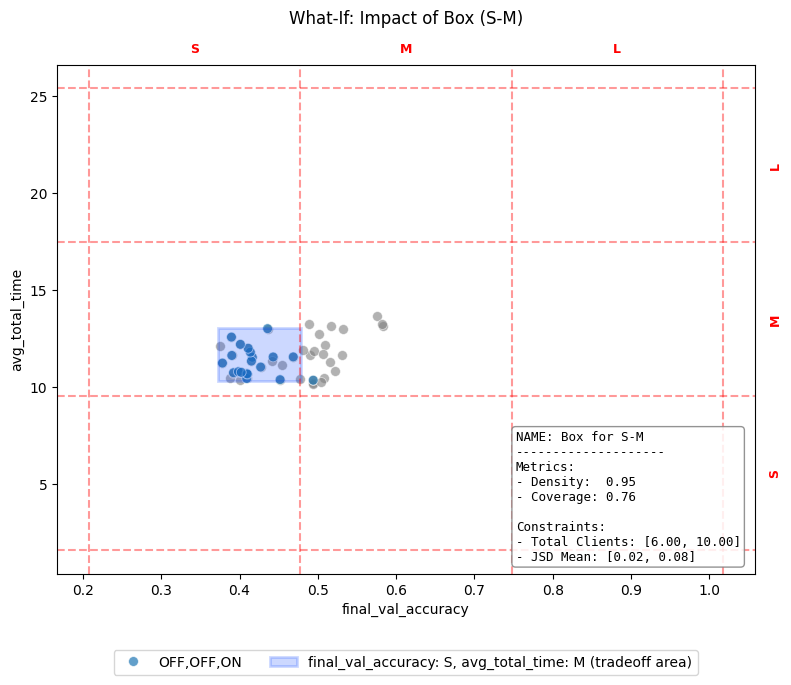

In [43]:
# Visualization of an example box: the first tradeoff that has a CART box
# (cart_box_list is aligned with `tradeoffs`; tradeoffs without a box hold None)
example = next(((box, t) for box, t in zip(cart_box_list, tradeoffs) if box is not None), None)
if example is None:
    print("No CART box to visualize.")
else:
    example_box, example_tradeoff = example
    for x_col, y_col in itertools.combinations(outcome_cols, 2):
        session.show_box_impact_objective_space(
            box=example_box,
            x_metric=x_col, 
            y_metric=y_col,
            tradeoff=session.get_tradeoff(example_tradeoff.name),
            show_box_summary=True,
            subset='test',
            cmap='tab10', 
            alpha=0.7,
            figsize=(8, 7),
            s=50
        )
        plt.show()


## 12. Box Diagnostics and "Not Selected" Hatching

We first visualize the first non-empty discovered box (PRIM or CART). We then look for a box that also covers the "not selected" state of some optional parameter (`box.includes_na`), which the diagnostics plot draws as a hatched N/A region.

A box covers the "not selected" state when it describes runs where a pattern is OFF, e.g. a limit on `Client Selector Criteria` that includes its "not selected" value. The cell below renders the first such box, or reports that none was found.

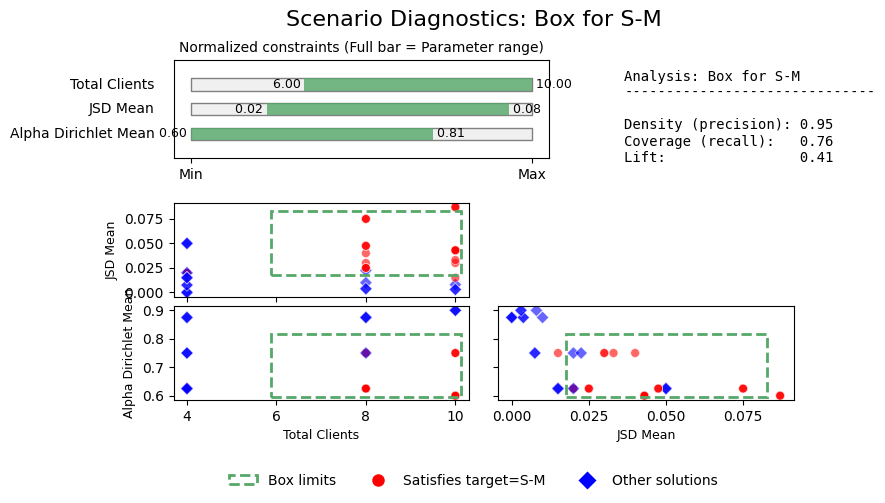

In [44]:
all_boxes = prim_boxes + cart_boxes

if all_boxes:
    first_box = all_boxes[0]
    fig = session.show_box_diagnostics(box=first_box, subset='test', show_policies=False, figsize=(8, 5))
    plt.show()
else:
    print("No non-empty boxes were discovered by PRIM or CART; skipping box diagnostics.")

In [45]:
# Boxes record which optional parameters they cover in the "not selected" state
# (box.includes_na); readable_limits() marks those parameters with includes_na.
na_hatching_box = next(
    ((box, param) for box in all_boxes for param, covered in box.includes_na.items() if covered),
    None
)

if na_hatching_box:
    box, param_name = na_hatching_box
    print(f"R10: box for {box.target_tradeoff} also covers '{param_name}' = not selected: "
          f"{box.readable_limits()[param_name]}. Rendering N/A-hatching diagnostics:")
    fig = session.show_box_diagnostics(box=box, subset='test', show_policies=False, figsize=(8, 5))
    plt.show()
else:
    print("R10: no PRIM/CART box discovered in this run covers an optional parameter's "
          "'not selected' state, so there is no N/A region to hatch.")

R10: no PRIM/CART box discovered in this run covers an optional parameter's 'not selected' state, so there is no N/A region to hatch.


/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_43117/390917906.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_43117/390917906.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


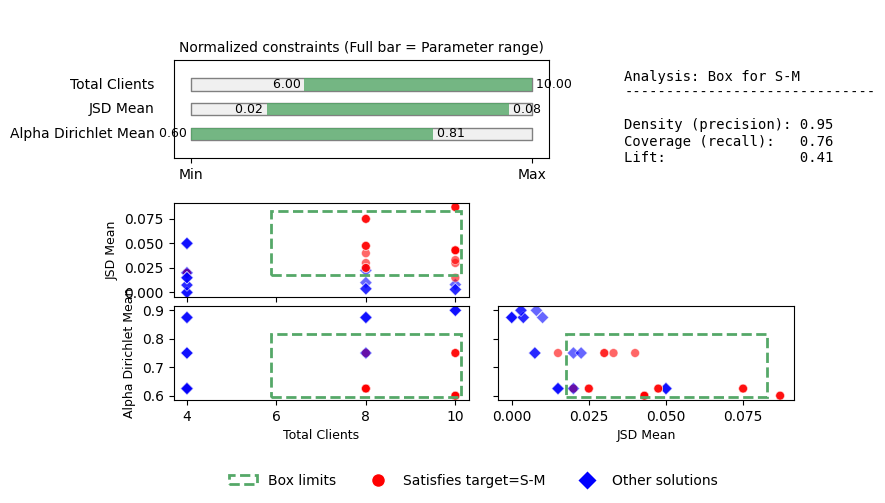

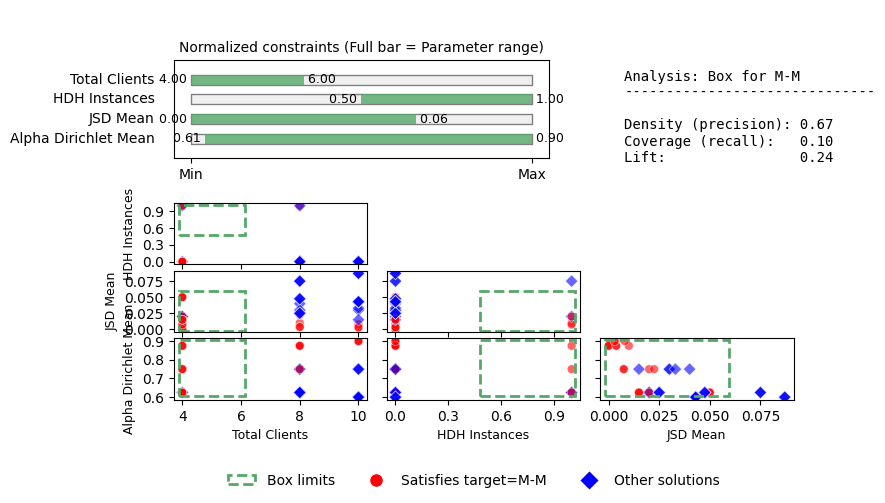

In [46]:
for box in prim_boxes: # Inspect PRIM boxes
    fig = session.show_box_diagnostics(box, subset='test', show_policies=False, figsize=(8,5), title=" ") #, palette='tab10')
    fig.show()

/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_43117/534013300.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_43117/534013300.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


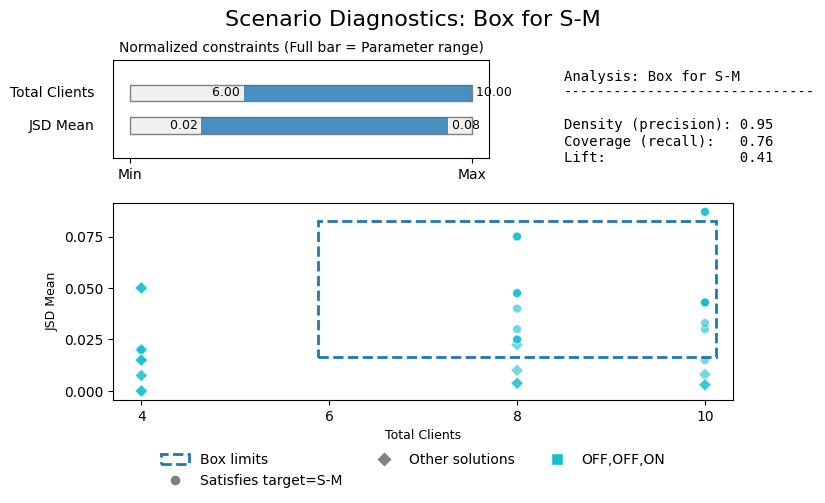

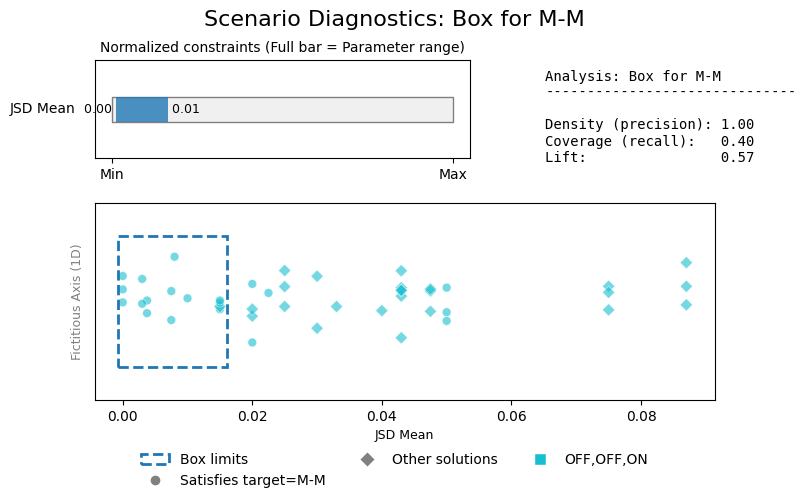

In [47]:
for box in cart_boxes: # Inspect CART boxes
    fig = session.show_box_diagnostics(box, subset='test', show_policies=True, figsize=(8,5)) #, palette='tab10')
    fig.show()

## 13. Performance Metrics

In [48]:
# PRIM
scores = session.get_algorithm_performance_scores(prim_boxes, return_std=True, subset='test')
metrics_df = pd.DataFrame(scores.items(), columns=['metric', 'value'])
df = metrics_df.T
prim_df = pd.DataFrame(df.values[1:], columns=df.iloc[0])
metrics_df

2 tradeoffs to evaluate. 2 2


,metric,value
0,precision,0.808333
1,recall,0.430000
2,f1,0.509179
3,lift,0.308333
4,complexity,3.500000
5,success_rate,1.000000
6,precision_std,0.141667
7,recall_std,0.330000
8,f1_std,0.335266
9,lift_std,0.086111


In [49]:
# CART
scores = session.get_algorithm_performance_scores(cart_boxes, return_std=True, subset='test')
metrics_df = pd.DataFrame(scores.items(), columns=['metric', 'value'])
df = metrics_df.T
cart_df = pd.DataFrame(df.values[1:], columns=df.iloc[0])
metrics_df


2 tradeoffs to evaluate. 2 2


,metric,value
0,precision,0.975000
1,recall,0.580000
2,f1,0.707937
3,lift,0.475000
4,complexity,1.500000
5,success_rate,1.000000
6,precision_std,0.025000
7,recall_std,0.180000
8,f1_std,0.136508
9,lift_std,0.080556


In [50]:
all_metrics = pd.concat([prim_df, cart_df], axis=0)
all_metrics.index = ['prim', 'cart']
# all_metrics.to_csv('metrics-fl.csv', decimal=',')
all_metrics

metric,precision,recall,f1,lift,complexity,success_rate,precision_std,recall_std,f1_std,lift_std,complexity_std
prim,0.808333,0.43,0.509179,0.308333,3.5,1.0,0.141667,0.33,0.335266,0.086111,0.5
cart,0.975,0.58,0.707937,0.475,1.5,1.0,0.025,0.18,0.136508,0.080556,0.5
